In [1]:
# ============================================
# Amazon Phone Market Analysis
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

pd.set_option("display.max_columns", None)

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
# ============================================
# 1. Read Dataset
# ============================================

file_path = "phone search (1).csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (340, 20)


In [4]:
# Check the data
df.head()

,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,product_availability,climate_pledge_friendly,sales_volume,delivery,has_variations,unit_price,unit_count,coupon_text
0,B0BQ118F2T,Moto G Play 2023 3-Day Battery Unlocked Made f...,$99.00,$169.99,USD,4.0,1319,16,$69.88,False,False,True,Only 1 left in stock - order soon.,False,4K+ bought in past month,"FREE delivery Tue, Sep 24 Only 1 left in stock...",False,NaN,NaN,NaN
1,B0CV2W1TKZ,"Samsung Galaxy A15 (SM-155M/DSN), 128GB 6GB RA...",$153.99,NaN,USD,4.2,186,4,$147.50,False,False,True,NaN,False,1K+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN
2,B09SM24S8C,"Samsung Galaxy A03s Cell Phone, AT&amp;T GSM U...",$69.00,$99.99,USD,3.8,597,35,$64.99,False,False,True,NaN,False,2K+ bought in past month,"FREE delivery Tue, Sep 24",True,NaN,NaN,NaN
3,B0CHH1N9VY,TracFone | Motorola Moto g Pure | Locked | 32G...,$49.99,NaN,USD,4.2,2814,3,$43.99,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN
4,B09T3MQSVP,"Samsung Galaxy A13 5G Cell Phone, AT&amp;T GSM...",$88.09,$98.27,USD,3.8,1338,31,$70.40,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Mon, Sep 30",False,NaN,NaN,NaN


In [5]:
# Check rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 340
Columns: 20


In [6]:
# Check column names
df.columns

Index(['asin', 'product_title', 'product_price', 'product_original_price',
       'currency', 'product_star_rating', 'product_num_ratings',
       'product_num_offers', 'product_minimum_offer_price', 'is_best_seller',
       'is_amazon_choice', 'is_prime', 'product_availability',
       'climate_pledge_friendly', 'sales_volume', 'delivery', 'has_variations',
       'unit_price', 'unit_count', 'coupon_text'],
      dtype='str')

In [7]:
# ============================================
# 2. Data Information
# ============================================

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   asin                         340 non-null    str    
 1   product_title                340 non-null    str    
 2   product_price                336 non-null    str    
 3   product_original_price       148 non-null    str    
 4   currency                     336 non-null    str    
 5   product_star_rating          337 non-null    float64
 6   product_num_ratings          340 non-null    int64  
 7   product_num_offers           340 non-null    int64  
 8   product_minimum_offer_price  336 non-null    str    
 9   is_best_seller               340 non-null    bool   
 10  is_amazon_choice             340 non-null    bool   
 11  is_prime                     340 non-null    bool   
 12  product_availability         75 non-null     str    
 13  climate_pledge_friendly      34

In [8]:
# Statistical summary
df.describe(include="all")

,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,product_availability,climate_pledge_friendly,sales_volume,delivery,has_variations,unit_price,unit_count,coupon_text
count,340,340,336,148,336,337.000000,340.000000,340.000000,336,340,340,340,75,340,320,337,340,4,4.000000,22
unique,315,315,241,108,1,NaN,NaN,NaN,273,2,2,2,21,2,18,92,2,2,NaN,13
top,B0BQ118F2T,Moto G Play 2023 3-Day Battery Unlocked Made f...,$99.99,$119.99,USD,NaN,NaN,NaN,$99.99,False,False,True,Only 1 left in stock - order soon.,False,100+ bought in past month,"FREE delivery Tue, Sep 24",False,$25.00,NaN,Save 10% with coupon
freq,2,2,12,8,336,NaN,NaN,NaN,7,338,338,248,13,262,49,142,240,2,NaN,4
mean,NaN,NaN,NaN,NaN,NaN,4.087537,2744.050000,8.426471,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.500000,NaN
std,NaN,NaN,NaN,NaN,NaN,0.383544,7331.816833,10.798389,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.732051,NaN
min,NaN,NaN,NaN,NaN,NaN,1.600000,0.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,3.900000,135.250000,1.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,4.100000,503.500000,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.500000,NaN
75%,NaN,NaN,NaN,NaN,NaN,4.300000,1874.250000,11.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN


In [9]:
# ============================================
# 3. Missing Values
# ============================================

missing = df.isnull().sum()

print(missing)

asin                             0
product_title                    0
product_price                    4
product_original_price         192
currency                         4
product_star_rating              3
product_num_ratings              0
product_num_offers               0
product_minimum_offer_price      4
is_best_seller                   0
is_amazon_choice                 0
is_prime                         0
product_availability           265
climate_pledge_friendly          0
sales_volume                    20
delivery                         3
has_variations                   0
unit_price                     336
unit_count                     336
coupon_text                    318
dtype: int64


In [10]:
# Missing values percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage.round(2)
})

missing_table.sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Percentage
unit_count,336,98.82
unit_price,336,98.82
coupon_text,318,93.53
product_availability,265,77.94
product_original_price,192,56.47
sales_volume,20,5.88
product_price,4,1.18
currency,4,1.18
product_minimum_offer_price,4,1.18
product_star_rating,3,0.88


In [11]:
# ============================================
# 4. Duplicate Values
# ============================================

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 21


In [12]:
# Remove exact duplicates

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (319, 20)


In [13]:
# Check again
print("Duplicates remaining:", df.duplicated().sum())

Duplicates remaining: 0


In [14]:
# ============================================
# 5. Check Important Columns
# ============================================

print(df["currency"].value_counts(dropna=False))

print("\nPrime:")
print(df["is_prime"].value_counts())

print("\nBest Seller:")
print(df["is_best_seller"].value_counts())

print("\nAmazon Choice:")
print(df["is_amazon_choice"].value_counts())

currency
USD    315
NaN      4
Name: count, dtype: int64

Prime:
is_prime
True     231
False     88
Name: count, dtype: int64

Best Seller:
is_best_seller
False    317
True       2
Name: count, dtype: int64

Amazon Choice:
is_amazon_choice
False    318
True       1
Name: count, dtype: int64


In [15]:
# ============================================
# 6. Convert Price Columns
# ============================================

def clean_price(value):
    if pd.isna(value):
        return np.nan
    
    value = str(value)
    value = re.sub(r"[^0-9.]", "", value)
    
    if value == "":
        return np.nan
    
    return float(value)

In [16]:
# Apply the function

df["product_price_num"] = df["product_price"].apply(clean_price)

df["product_original_price_num"] = (
    df["product_original_price"].apply(clean_price)
)

df["product_minimum_offer_price_num"] = (
    df["product_minimum_offer_price"].apply(clean_price)
)

df["unit_price_num"] = (
    df["unit_price"].apply(clean_price)
)

print("Price columns converted successfully")

Price columns converted successfully


In [17]:
# Check the result

df[
    [
        "product_price",
        "product_price_num",
        "product_original_price",
        "product_original_price_num"
    ]
].head(10)

,product_price,product_price_num,product_original_price,product_original_price_num
0,$99.00,99.00,$169.99,169.99
1,$153.99,153.99,NaN,NaN
2,$69.00,69.00,$99.99,99.99
3,$49.99,49.99,NaN,NaN
4,$88.09,88.09,$98.27,98.27
5,$49.99,49.99,$59.99,59.99
6,$149.99,149.99,$249.99,249.99
7,$149.50,149.50,$158.00,158.00
8,$139.99,139.99,NaN,NaN
9,$59.99,59.99,NaN,NaN


In [18]:
# Check data types

df[
    [
        "product_price_num",
        "product_original_price_num",
        "product_minimum_offer_price_num",
        "unit_price_num"
    ]
].dtypes

product_price_num                  float64
product_original_price_num         float64
product_minimum_offer_price_num    float64
unit_price_num                     float64
dtype: object

In [19]:
# ============================================
# 7. Sales Volume
# ============================================

def clean_sales(value):
    if pd.isna(value):
        return np.nan
    
    value = str(value).lower()
    
    match = re.search(r"(\d+(?:\.\d+)?)\s*(k|m)?", value)
    
    if not match:
        return np.nan
    
    number = float(match.group(1))
    unit = match.group(2)
    
    if unit == "k":
        number = number * 1000
    elif unit == "m":
        number = number * 1000000
    
    return number

In [20]:
# Create numeric sales volume

df["sales_volume_num"] = (
    df["sales_volume"].apply(clean_sales)
)

df[
    [
        "sales_volume",
        "sales_volume_num"
    ]
].head(20)

,sales_volume,sales_volume_num
0,4K+ bought in past month,4000.0
1,1K+ bought in past month,1000.0
2,2K+ bought in past month,2000.0
3,500+ bought in past month,500.0
4,500+ bought in past month,500.0
5,4K+ bought in past month,4000.0
6,2K+ bought in past month,2000.0
7,500+ bought in past month,500.0
8,1K+ bought in past month,1000.0
9,1K+ bought in past month,1000.0


In [21]:
# Check sales volume

print(
    df["sales_volume_num"].describe()
)

count     274.000000
mean      495.620438
std       692.661017
min        50.000000
25%       100.000000
50%       300.000000
75%       500.000000
max      4000.000000
Name: sales_volume_num, dtype: float64


In [22]:
# ============================================
# 8. Discount
# ============================================

df["discount_amount"] = (
    df["product_original_price_num"]
    - df["product_price_num"]
)

df["discount_percent"] = (
    df["discount_amount"]
    / df["product_original_price_num"]
) * 100

# Remove negative values
df.loc[
    df["discount_percent"] < 0,
    "discount_percent"
] = np.nan

df.loc[
    df["discount_amount"] < 0,
    "discount_amount"
] = np.nan

In [23]:
# Check discount calculation

df[
    [
        "product_price_num",
        "product_original_price_num",
        "discount_amount",
        "discount_percent"
    ]
].head(10)

,product_price_num,product_original_price_num,discount_amount,discount_percent
0,99.00,169.99,70.99,41.761280
1,153.99,NaN,NaN,NaN
2,69.00,99.99,30.99,30.993099
3,49.99,NaN,NaN,NaN
4,88.09,98.27,10.18,10.359214
5,49.99,59.99,10.00,16.669445
6,149.99,249.99,100.00,40.001600
7,149.50,158.00,8.50,5.379747
8,139.99,NaN,NaN,NaN
9,59.99,NaN,NaN,NaN


In [24]:
# ============================================
# 9. Create Simple Features
# ============================================

df["has_discount"] = (
    df["discount_percent"] > 0
)

df["has_coupon"] = (
    df["coupon_text"].notna()
)

print(df["has_discount"].value_counts())
print()
print(df["has_coupon"].value_counts())

has_discount
False    180
True     139
Name: count, dtype: int64

has_coupon
False    297
True      22
Name: count, dtype: int64


In [25]:
# ============================================
# 10. Price Categories
# ============================================

def price_category(price):
    
    if pd.isna(price):
        return "Unknown"
    
    if price < 100:
        return "Under $100"
    
    elif price < 300:
        return "$100 - $299"
    
    elif price < 600:
        return "$300 - $599"
    
    else:
        return "$600+"

df["price_category"] = (
    df["product_price_num"]
    .apply(price_category)
)

df["price_category"].value_counts()

price_category
Under $100     152
$100 - $299    123
$300 - $599     26
$600+           14
Unknown          4
Name: count, dtype: int64

In [26]:
# ============================================
# 11. Rating Categories
# ============================================

def rating_category(rating):
    
    if pd.isna(rating):
        return "Unknown"
    
    if rating < 3:
        return "Low"
    
    elif rating < 4:
        return "Average"
    
    elif rating < 4.5:
        return "Good"
    
    else:
        return "Excellent"

df["rating_category"] = (
    df["product_star_rating"]
    .apply(rating_category)
)

df["rating_category"].value_counts()

rating_category
Good         198
Average       86
Excellent     29
Unknown        3
Low            3
Name: count, dtype: int64

In [27]:
# ============================================
# 12. Check Cleaned Dataset
# ============================================

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 319
Columns: 31


,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,product_availability,climate_pledge_friendly,sales_volume,delivery,has_variations,unit_price,unit_count,coupon_text,product_price_num,product_original_price_num,product_minimum_offer_price_num,unit_price_num,sales_volume_num,discount_amount,discount_percent,has_discount,has_coupon,price_category,rating_category
0,B0BQ118F2T,Moto G Play 2023 3-Day Battery Unlocked Made f...,$99.00,$169.99,USD,4.0,1319,16,$69.88,False,False,True,Only 1 left in stock - order soon.,False,4K+ bought in past month,"FREE delivery Tue, Sep 24 Only 1 left in stock...",False,NaN,NaN,NaN,99.00,169.99,69.88,NaN,4000.0,70.99,41.761280,True,False,Under $100,Good
1,B0CV2W1TKZ,"Samsung Galaxy A15 (SM-155M/DSN), 128GB 6GB RA...",$153.99,NaN,USD,4.2,186,4,$147.50,False,False,True,NaN,False,1K+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN,153.99,NaN,147.50,NaN,1000.0,NaN,NaN,False,False,$100 - $299,Good
2,B09SM24S8C,"Samsung Galaxy A03s Cell Phone, AT&amp;T GSM U...",$69.00,$99.99,USD,3.8,597,35,$64.99,False,False,True,NaN,False,2K+ bought in past month,"FREE delivery Tue, Sep 24",True,NaN,NaN,NaN,69.00,99.99,64.99,NaN,2000.0,30.99,30.993099,True,False,Under $100,Average
3,B0CHH1N9VY,TracFone | Motorola Moto g Pure | Locked | 32G...,$49.99,NaN,USD,4.2,2814,3,$43.99,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN,49.99,NaN,43.99,NaN,500.0,NaN,NaN,False,False,Under $100,Good
4,B09T3MQSVP,"Samsung Galaxy A13 5G Cell Phone, AT&amp;T GSM...",$88.09,$98.27,USD,3.8,1338,31,$70.40,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Mon, Sep 30",False,NaN,NaN,NaN,88.09,98.27,70.40,NaN,500.0,10.18,10.359214,True,False,Under $100,Average


In [28]:
# Check duplicates again

print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [29]:
# Check missing values again

df.isnull().sum()

asin                                 0
product_title                        0
product_price                        4
product_original_price             180
currency                             4
product_star_rating                  3
product_num_ratings                  0
product_num_offers                   0
product_minimum_offer_price          4
is_best_seller                       0
is_amazon_choice                     0
is_prime                             0
product_availability               245
climate_pledge_friendly              0
sales_volume                        19
delivery                             3
has_variations                       0
unit_price                         317
unit_count                         317
coupon_text                        297
product_price_num                    4
product_original_price_num         180
product_minimum_offer_price_num      4
unit_price_num                     317
sales_volume_num                    45
discount_amount          

In [30]:
# ============================================
# 13. Basic Analysis
# ============================================

print("Average Price:",
      round(df["product_price_num"].mean(), 2))

print("Median Price:",
      round(df["product_price_num"].median(), 2))

print("Average Rating:",
      round(df["product_star_rating"].mean(), 2))

print("Average Number of Offers:",
      round(df["product_num_offers"].mean(), 2))

print("Total Customer Ratings:",
      df["product_num_ratings"].sum())

Average Price: 173.59
Median Price: 113.87
Average Rating: 4.08
Average Number of Offers: 8.45
Total Customer Ratings: 881894


In [31]:
# ============================================
# 14. Price Analysis
# ============================================

df["price_category"].value_counts()

price_category
Under $100     152
$100 - $299    123
$300 - $599     26
$600+           14
Unknown          4
Name: count, dtype: int64

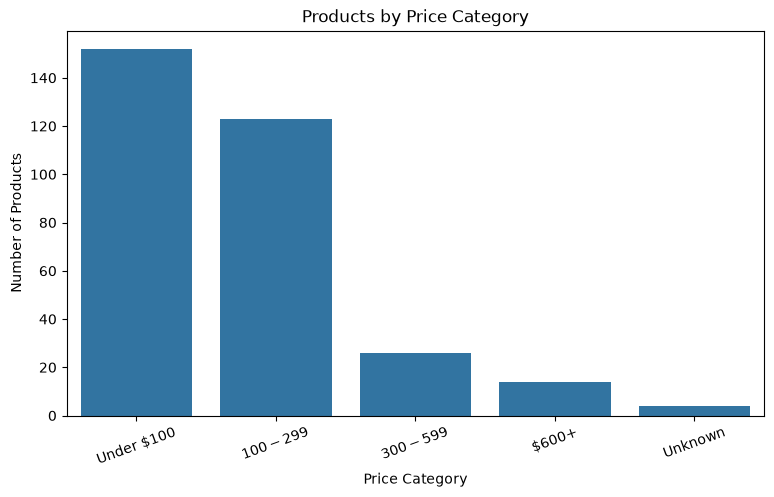

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="price_category"
)

plt.title("Products by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Products")

plt.xticks(rotation=20)
plt.show()

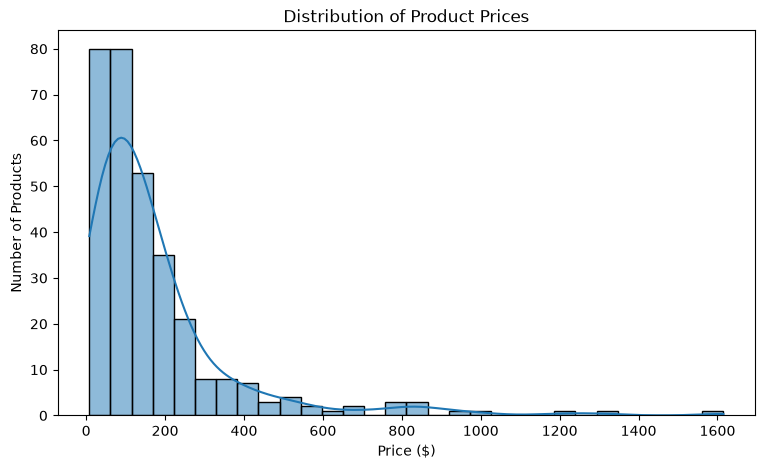

In [33]:
# ============================================
# 15. Price Distribution
# ============================================

plt.figure(figsize=(9, 5))

sns.histplot(
    df["product_price_num"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Product Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Products")

plt.show()

In [34]:
# ============================================
# 16. Rating Analysis
# ============================================

df["rating_category"].value_counts()

rating_category
Good         198
Average       86
Excellent     29
Unknown        3
Low            3
Name: count, dtype: int64

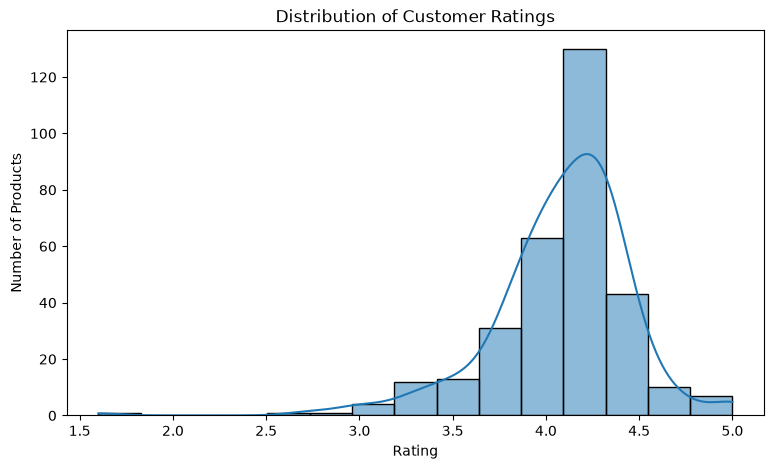

In [35]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["product_star_rating"].dropna(),
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.show()

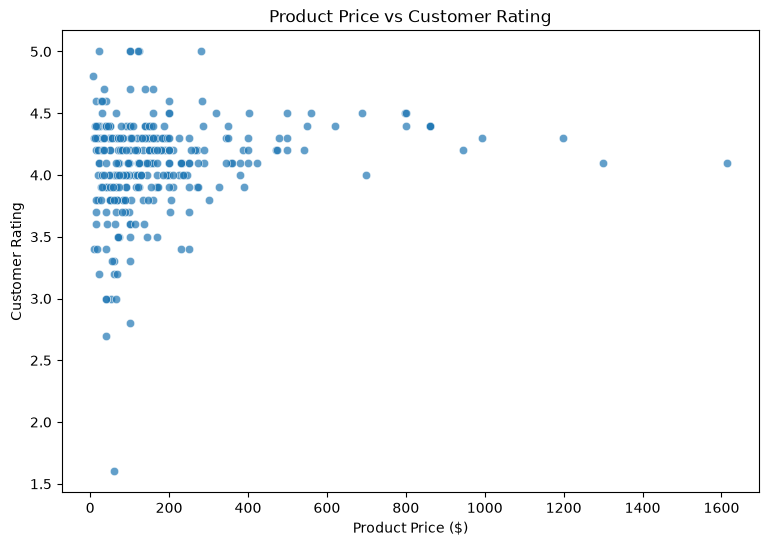

In [36]:
# ============================================
# 17. Price vs Rating
# ============================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="product_price_num",
    y="product_star_rating",
    alpha=0.7
)

plt.title("Product Price vs Customer Rating")
plt.xlabel("Product Price ($)")
plt.ylabel("Customer Rating")

plt.show()

In [37]:
# Correlation between price and rating

price_rating_corr = df[
    [
        "product_price_num",
        "product_star_rating"
    ]
].corr()

price_rating_corr

,product_price_num,product_star_rating
product_price_num,1.000000,0.183936
product_star_rating,0.183936,1.000000


In [38]:
# ============================================
# 18. Prime Analysis
# ============================================

prime_analysis = df.groupby("is_prime").agg(
    Products=("asin", "count"),
    Average_Price=("product_price_num", "mean"),
    Average_Rating=("product_star_rating", "mean"),
    Average_Offers=("product_num_offers", "mean")
)

prime_analysis

,Products,Average_Price,Average_Rating,Average_Offers
is_prime,,,,
False,88,232.925412,4.072093,12.465909
True,231,151.666913,4.088261,6.917749


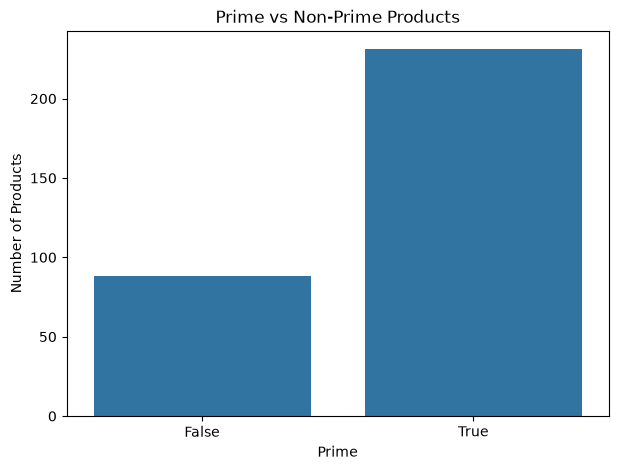

In [39]:
# Prime products chart

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="is_prime"
)

plt.title("Prime vs Non-Prime Products")
plt.xlabel("Prime")
plt.ylabel("Number of Products")

plt.show()

In [40]:
# ============================================
# 19. Best Seller Analysis
# ============================================

best_seller_analysis = df.groupby(
    "is_best_seller"
).agg(
    Products=("asin", "count"),
    Average_Price=("product_price_num", "mean"),
    Average_Rating=("product_star_rating", "mean"),
    Average_Ratings_Count=("product_num_ratings", "mean")
)

best_seller_analysis

,Products,Average_Price,Average_Rating,Average_Ratings_Count
is_best_seller,,,,
False,317,173.689329,4.082166,2609.432177
True,2,158.645000,4.350000,27352.000000


In [41]:
# ============================================
# 20. Top 10 Products
# ============================================

top_10 = df.sort_values(
    "product_num_ratings",
    ascending=False
).head(10)

top_10[
    [
        "product_title",
        "product_price_num",
        "product_star_rating",
        "product_num_ratings",
        "is_prime",
        "is_best_seller"
    ]
]

,product_title,product_price_num,product_star_rating,product_num_ratings,is_prime,is_best_seller
75,"Apple iPhone XR, 64GB, Black - Unlocked (Renewed)",187.00,4.4,64977,False,False
271,Scosche MAGWSM2 MagicMount Magnetic Suction Cu...,11.99,4.4,53768,True,False
165,"Apple iPhone 11, US Version, 64GB, Black - T-M...",209.00,4.2,52783,False,False
153,[New] VTech VG131-21 DECT 6.0 2-Handset Cordle...,30.52,4.2,40734,True,False
169,VTech CS6719-16 DECT 6.0 Phone with Caller ID/...,20.23,4.4,37768,True,False
338,"Sensyne 92&quot; Cell Phone Tripod, Selfie Sti...",29.99,4.6,29066,True,True
35,AT&amp;T BL102-3 DECT 6.0 3-Handset Cordless P...,78.95,4.3,27240,False,False
163,VTech CS6529-3 3-Handset Expandable Cordless P...,65.95,4.3,26175,True,False
63,"Apple iPhone 12, 128GB, Black - Fully Unlocked...",287.30,4.1,25638,False,True
128,AT&amp;T CL82507 DECT 6.0 5-Handset Cordless P...,117.77,4.3,20608,True,False


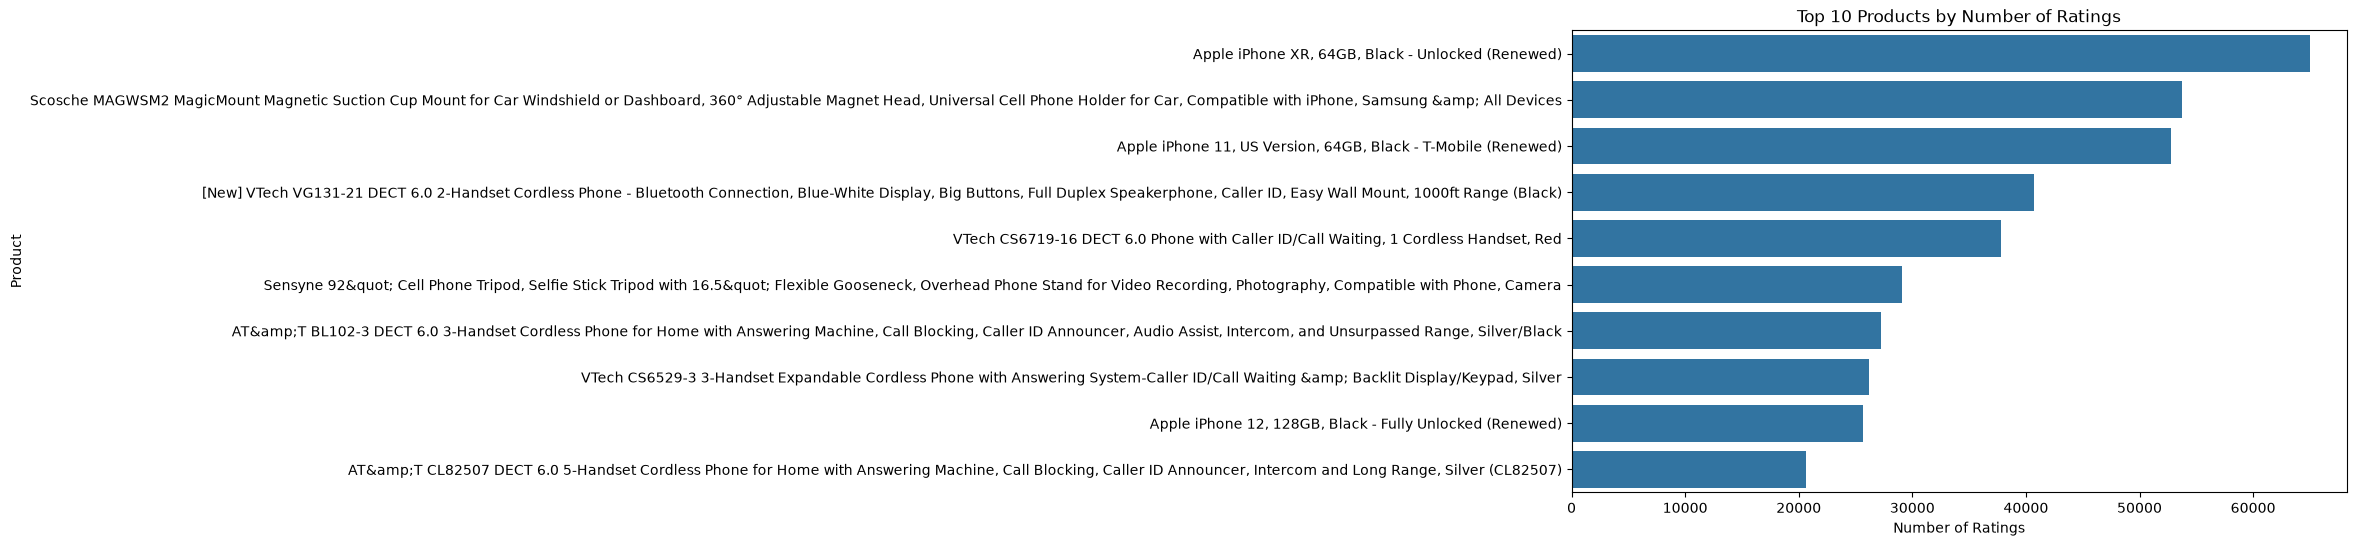

In [42]:
# Top 10 chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="product_num_ratings",
    y="product_title"
)

plt.title("Top 10 Products by Number of Ratings")
plt.xlabel("Number of Ratings")
plt.ylabel("Product")

plt.show()

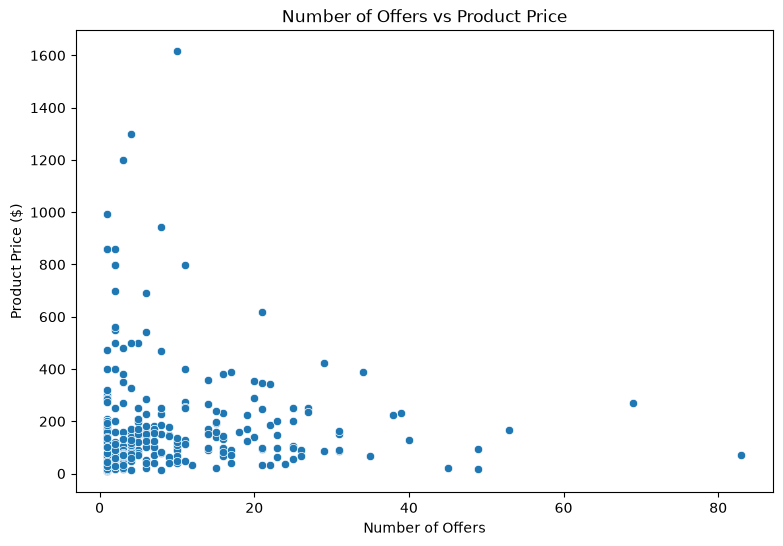

In [43]:
# ============================================
# 21. Offers vs Price
# ============================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="product_num_offers",
    y="product_price_num"
)

plt.title("Number of Offers vs Product Price")
plt.xlabel("Number of Offers")
plt.ylabel("Product Price ($)")

plt.show()

In [44]:
# ============================================
# 22. Discount Analysis
# ============================================

print("Products with discount:")
print(df["has_discount"].value_counts())

print("\nAverage discount:")
print(
    round(
        df["discount_percent"].mean(),
        2
    )
)

Products with discount:
has_discount
False    180
True     139
Name: count, dtype: int64

Average discount:
20.82


In [45]:
# ============================================
# 23. Correlation Matrix
# ============================================

numeric_columns = [
    "product_price_num",
    "product_star_rating",
    "product_num_ratings",
    "product_num_offers",
    "sales_volume_num",
    "discount_percent"
]

correlation = df[numeric_columns].corr()

correlation

,product_price_num,product_star_rating,product_num_ratings,product_num_offers,sales_volume_num,discount_percent
product_price_num,1.000000,0.183936,-0.069140,-0.004175,-0.073096,-0.052548
product_star_rating,0.183936,1.000000,0.160292,-0.026777,0.037750,-0.163249
product_num_ratings,-0.069140,0.160292,1.000000,0.073697,0.157995,-0.164842
product_num_offers,-0.004175,-0.026777,0.073697,1.000000,0.215998,0.067021
sales_volume_num,-0.073096,0.037750,0.157995,0.215998,1.000000,0.135591
discount_percent,-0.052548,-0.163249,-0.164842,0.067021,0.135591,1.000000


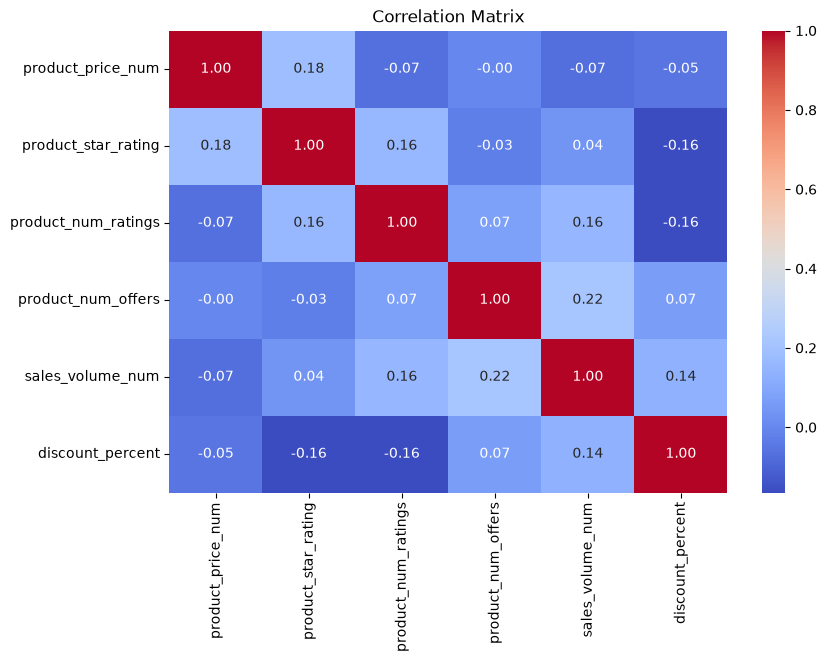

In [46]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [47]:
# ============================================
# 24. Important Business Summary
# ============================================

print("Total Products:",
      df["asin"].nunique())

print(
    "Average Price: $",
    round(df["product_price_num"].mean(), 2)
)

print(
    "Average Rating:",
    round(df["product_star_rating"].mean(), 2)
)

print(
    "Average Offers:",
    round(df["product_num_offers"].mean(), 2)
)

print(
    "Prime Products:",
    df["is_prime"].sum()
)

print(
    "Best Seller Products:",
    df["is_best_seller"].sum()
)

print(
    "Products With Discounts:",
    df["has_discount"].sum()
)

print(
    "Products With Coupons:",
    df["has_coupon"].sum()
)

Total Products: 315
Average Price: $ 173.59
Average Rating: 4.08
Average Offers: 8.45
Prime Products: 231
Best Seller Products: 2
Products With Discounts: 139
Products With Coupons: 22


In [48]:
# ============================================
# 25. Final Data Check
# ============================================

print("Final Shape:", df.shape)

print("Duplicates:",
      df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

Final Shape: (319, 31)
Duplicates: 0

Missing Values:
asin                                 0
product_title                        0
product_price                        4
product_original_price             180
currency                             4
product_star_rating                  3
product_num_ratings                  0
product_num_offers                   0
product_minimum_offer_price          4
is_best_seller                       0
is_amazon_choice                     0
is_prime                             0
product_availability               245
climate_pledge_friendly              0
sales_volume                        19
delivery                             3
has_variations                       0
unit_price                         317
unit_count                         317
coupon_text                        297
product_price_num                    4
product_original_price_num         180
product_minimum_offer_price_num      4
unit_price_num                     317
sales_volu

In [49]:
# ============================================
# 26. Save Cleaned Dataset
# ============================================

output_file = "cleaned_phone_data.csv"

df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved successfully:")
print(output_file)

Cleaned dataset saved successfully:
cleaned_phone_data.csv


In [50]:
# Check saved file

check_df = pd.read_csv(output_file)

print("Saved file shape:", check_df.shape)

check_df.head()

Saved file shape: (319, 31)


,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,product_availability,climate_pledge_friendly,sales_volume,delivery,has_variations,unit_price,unit_count,coupon_text,product_price_num,product_original_price_num,product_minimum_offer_price_num,unit_price_num,sales_volume_num,discount_amount,discount_percent,has_discount,has_coupon,price_category,rating_category
0,B0BQ118F2T,Moto G Play 2023 3-Day Battery Unlocked Made f...,$99.00,$169.99,USD,4.0,1319,16,$69.88,False,False,True,Only 1 left in stock - order soon.,False,4K+ bought in past month,"FREE delivery Tue, Sep 24 Only 1 left in stock...",False,NaN,NaN,NaN,99.00,169.99,69.88,NaN,4000.0,70.99,41.761280,True,False,Under $100,Good
1,B0CV2W1TKZ,"Samsung Galaxy A15 (SM-155M/DSN), 128GB 6GB RA...",$153.99,NaN,USD,4.2,186,4,$147.50,False,False,True,NaN,False,1K+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN,153.99,NaN,147.50,NaN,1000.0,NaN,NaN,False,False,$100 - $299,Good
2,B09SM24S8C,"Samsung Galaxy A03s Cell Phone, AT&amp;T GSM U...",$69.00,$99.99,USD,3.8,597,35,$64.99,False,False,True,NaN,False,2K+ bought in past month,"FREE delivery Tue, Sep 24",True,NaN,NaN,NaN,69.00,99.99,64.99,NaN,2000.0,30.99,30.993099,True,False,Under $100,Average
3,B0CHH1N9VY,TracFone | Motorola Moto g Pure | Locked | 32G...,$49.99,NaN,USD,4.2,2814,3,$43.99,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN,49.99,NaN,43.99,NaN,500.0,NaN,NaN,False,False,Under $100,Good
4,B09T3MQSVP,"Samsung Galaxy A13 5G Cell Phone, AT&amp;T GSM...",$88.09,$98.27,USD,3.8,1338,31,$70.40,False,False,True,NaN,False,500+ bought in past month,"FREE delivery Mon, Sep 30",False,NaN,NaN,NaN,88.09,98.27,70.40,NaN,500.0,10.18,10.359214,True,False,Under $100,Average


In [51]:
# ============================================
# 27. Final Verification
# ============================================

print("Original rows: 340")
print("Final rows:", len(df))

print("Duplicates remaining:",
      df.duplicated().sum())

print(
    "Cleaned file columns:",
    len(df.columns)
)

print("\nPython analysis completed successfully.")

Original rows: 340
Final rows: 319
Duplicates remaining: 0
Cleaned file columns: 31

Python analysis completed successfully.
